In [ ]:
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, accuracy_score

In [ ]:
iris = load_iris()
X = iris.data
y = iris.target

In [ ]:
iris_df = pd.DataFrame(X, columns=iris.feature_names)
iris_df['species'] = [iris.target_names[label] for label in y]

In [ ]:
print("Top 5 rows of the Iris dataset:")
iris_df.head()

Top 5 rows of the Iris dataset:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [ ]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [ ]:
X_train

array([[-0.4134164 , -1.46200287, -0.09951105, -0.32339776],
       [ 0.55122187, -0.50256349,  0.71770262,  0.35303182],
       [ 0.67180165,  0.21701605,  0.95119225,  0.75888956],
       [ 0.91296121, -0.02284379,  0.30909579,  0.2177459 ],
       [ 1.63643991,  1.41631528,  1.30142668,  1.70589097],
       [-0.17225683, -0.26270364,  0.19235097,  0.08245999],
       [ 2.11875905, -0.02284379,  1.59328871,  1.16474731],
       [-0.29283662, -0.02284379,  0.36746819,  0.35303182],
       [-0.89573553,  1.17645543, -1.44207638, -1.40568508],
       [ 2.23933883, -0.50256349,  1.65166111,  1.0294614 ],
       [-0.05167705, -0.74242333,  0.13397857, -0.32339776],
       [-0.77515575,  0.93659559, -1.44207638, -1.40568508],
       [-1.01631531,  1.17645543, -1.50044878, -1.27039917],
       [-0.89573553,  1.89603497, -1.15021435, -1.13511325],
       [-1.01631531, -2.42144225, -0.21625586, -0.32339776],
       [ 0.55122187, -0.74242333,  0.60095781,  0.75888956],
       [-1.25747488,  0.

In [ ]:
X_test

array([[ 0.3100623 , -0.50256349,  0.484213  , -0.05282593],
       [-0.17225683,  1.89603497, -1.26695916, -1.27039917],
       [ 2.23933883, -0.98228318,  1.76840592,  1.43531914],
       [ 0.18948252, -0.26270364,  0.36746819,  0.35303182],
       [ 1.15412078, -0.50256349,  0.54258541,  0.2177459 ],
       [-0.53399618,  0.93659559, -1.38370397, -1.13511325],
       [-0.29283662, -0.26270364, -0.15788346,  0.08245999],
       [ 1.27470056,  0.21701605,  0.71770262,  1.43531914],
       [ 0.43064208, -1.94172256,  0.36746819,  0.35303182],
       [-0.05167705, -0.74242333,  0.01723376, -0.05282593],
       [ 0.79238143,  0.4568759 ,  0.71770262,  1.0294614 ],
       [-1.25747488, -0.02284379, -1.44207638, -1.540971  ],
       [-0.4134164 ,  1.17645543, -1.50044878, -1.40568508],
       [-1.1368951 ,  0.21701605, -1.38370397, -1.540971  ],
       [-0.89573553,  1.89603497, -1.38370397, -1.27039917],
       [ 0.55122187,  0.69673574,  0.484213  ,  0.48831773],
       [ 0.79238143, -0.

In [ ]:
k = 3
knn = KNeighborsClassifier(n_neighbors=k)

In [ ]:
knn.fit(X_train, y_train)

KNeighborsClassifier(n_neighbors=3)

In [ ]:
y_pred = knn.predict(X_test)

In [ ]:
print("\nAccuracy on test data:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))


Accuracy on test data: 1.0

Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        19
           1       1.00      1.00      1.00        13
           2       1.00      1.00      1.00        13

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45



In [ ]:
print("\nEnter values for prediction:")
print("Input the following values for a flower:")
sepal_length = float(input("Sepal Length (cm): "))
sepal_width = float(input("Sepal Width (cm): "))
petal_length = float(input("Petal Length (cm): "))
petal_width = float(input("Petal Width (cm): "))


Enter values for prediction:
Input the following values for a flower:
Sepal Length (cm): 4
Sepal Width (cm): 3
Petal Length (cm): 2
Petal Width (cm): 1


In [ ]:
user_input = scaler.transform([[sepal_length, sepal_width, petal_length, petal_width]])

In [ ]:
user_prediction = knn.predict(user_input)

In [ ]:
print(f"\nPredicted Species: {iris.target_names[user_prediction[0]]}")


Predicted Species: setosa


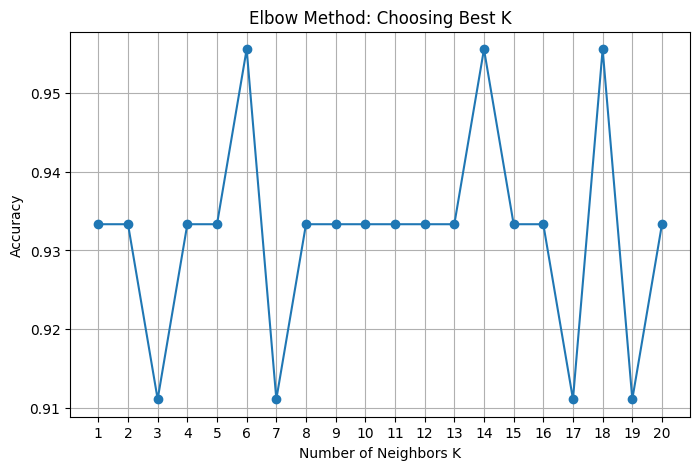

In [ ]:
k_values = range(1, 21)
accuracy_scores = []
import matplotlib.pyplot as plt
for k in k_values:
    knn_temp = KNeighborsClassifier(n_neighbors=k)
    knn_temp.fit(X_train, y_train)
    y_pred_temp = knn_temp.predict(X_test)
    accuracy_scores.append(accuracy_score(y_test, y_pred_temp))

plt.figure(figsize=(8, 5))
plt.plot(k_values, accuracy_scores, marker='o')
plt.title('Elbow Method: Choosing Best K')
plt.xlabel('Number of Neighbors K')
plt.ylabel('Accuracy')
plt.xticks(k_values)
plt.grid(True)
plt.show()